# Logistic Regression und Evaluation — Konzepte

Lies die Idee, die Formel und das kleine Beispiel in dieser Reihenfolge. Der Demonstrationscode ist vorhanden.

## Bibliotheken und Einstellungen

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, RocCurveDisplay

## 1. Von einem Score zu einer Wahrscheinlichkeit

Logistic regression (Wie wahrscheinlich ist es, dass ein Ereignis eintritt?) verwendet einen linearen score und eine S-förmige **sigmoid** Funktion:
$$z=\beta_0+\beta_1x,\qquad p=P(y=1\mid x)=\frac1{1+e^{-z}}.$$
$z$ ist der score; $p$ liegt zwischen 0 und 1. Für $\beta_0=-5$, $\beta_1=1$, $x=6$ gilt: $z=1$ und $p\approx0.73$. 

Die Wahrscheinlichkeit für Label 1 beträgt ungefähr 73 %.

Label 0: Ereignis tritt nicht ein

Label 1: Ereignis tritt ein

Ein positiver Koeffizient bedeutet, dass größere input values eine höhere predicted probability ergeben, wenn die anderen inputs konstant gehalten werden.

Mehrere inputs werden im score auf dieselbe Weise kombiniert wie bei multiple linear regression. Das Fitting verwendet maximum likelihood, was dem Minimieren von **log-loss** entspricht:
$$L(y,p)=-[y\log(p)+(1-y)\log(1-p)].$$
Für ein true positive ($y=1$) ist die prediction $p=0.9$ besser als $p=0.1$. Ein numerischer optimiser findet die Koeffizienten; wir verwenden `fit`.

Probability: 0.7310585786300049


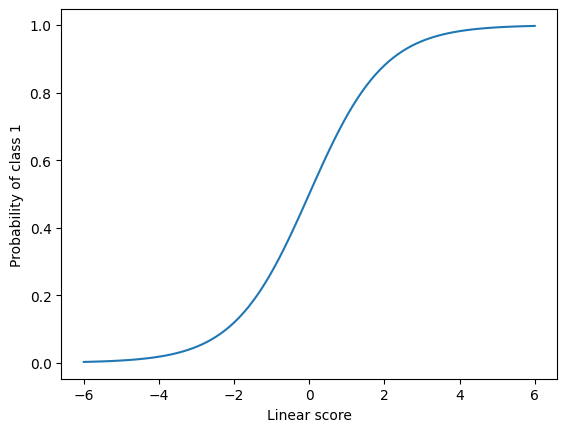

In [2]:
score = 1
print('Probability:', 1 / (1 + np.exp(-score)))
x = np.linspace(-6, 6, 100)
plt.plot(x, 1 / (1 + np.exp(-x)))
plt.xlabel('Linear score')
plt.ylabel('Probability of class 1')
plt.show()

## 2. Confusion matrix und metrics

Die Zeilen sind actual classes; die Spalten predicted classes:

| | Predicted 0 | Predicted 1 |
|---|---|---|
| Actual 0 | TN: correct negative | FP: false alarm |
| Actual 1 | FN: missed positive | TP: correct positive |

$$\mathrm{accuracy}=\frac{TP+TN}{TP+TN+FP+FN},\quad
\mathrm{precision}=\frac{TP}{TP+FP},\quad
\mathrm{recall}=\frac{TP}{TP+FN}.$$
$$\mathrm{FPR}=\frac{FP}{FP+TN},\qquad \mathrm{TPR}=\frac{TP}{TP+FN},\qquad F1=\frac{2\,\mathrm{precision}\,\mathrm{recall}}{\mathrm{precision}+\mathrm{recall}}.$$

Accuracy: Wie viele predictions (Vorhersagen) sind insgesamt korrekt? 

Precision: Wie viele predicted positives sind tatsächlich positives? 

Recall: Wie viele actual positives haben wir gefunden? 

FPR: Wie viele actual negatives wurden fälschlicherweise markiert? F1 gleicht precision und recall aus.

Bei TN=75, FP=22, FN=24 und TP=50 beträgt precision 50/72 und recall 50/74. Wenn positives selten sind, kann die prediction „always negative“ eine hohe accuracy, aber einen recall von null haben.

In [3]:
TN, FP, FN, TP = 75, 22, 24, 50
print('Accuracy:', (TP + TN) / (TP + TN + FP + FN))
print('Precision:', TP / (TP + FP))
print('Recall:', TP / (TP + FN))

Accuracy: 0.7309941520467836
Precision: 0.6944444444444444
Recall: 0.6756756756756757


## 3. Ein threshold macht aus einer Wahrscheinlichkeit eine class

Predict positive, wenn die geschätzte probability einen threshold $\tau$ erreicht:
$$\hat y=1\quad\mathrm{if}\quad p\geq\tau.$$
Bei $p=0.4$ ergibt ein threshold von 0.5 die prediction 0; ein threshold von 0.3 ergibt die prediction 1. Wird der threshold gesenkt, werden mehr positives gefunden, aber es können mehr false alarms entstehen. Recall und FPR können beim Senken des threshold nicht abnehmen. Precision kann beim Erhöhen des threshold steigen, dies ist jedoch nicht garantiert.

Wähle thresholds anhand von validation data und den Kosten der errors, zum Beispiel:
$$\mathrm{total\ cost}=c_{FN}\,FN+c_{FP}\,FP.$$
$c_{FN}$ und $c_{FP}$ sind die Kosten eines missed positive und eines false alarm. Wir vergleichen zur Veranschaulichung zwei feste thresholds; wir optimieren sie nicht auf dem test set.

## 4. ROC und AUC

Eine **ROC curve** stellt recall (true positive rate) für viele thresholds gegen FPR dar. Jeder threshold ergibt einen Punkt. Die Diagonale entspricht im Erwartungswert einem random ranking.

**AUC** ist die area under the curve. AUC = 0.5 bedeutet random ranking; AUC = 1 bedeutet perfect ranking. Es ist die Wahrscheinlichkeit, dass ein zufällig ausgewähltes positive einen höheren score erhält als ein zufällig ausgewähltes negative (ties zählen zur Hälfte). Verwende für ROC/AUC probabilities oder continuous scores, nicht nur 0/1 predictions.

## 5. Welche Informationen sind verfügbar?

Unser avalanche example sagt anhand der Anzahl vollständig verschütteter Personen einen fatal outcome **among recorded accidents** voraus. Diese Information ist nach einem accident verfügbar, nicht vor einer Tour.

Das model sagt nicht voraus, ob eine avalanche passieren wird. Um vor einem accident vorherzusagen, müssen die inputs zu diesem früheren Zeitpunkt verfügbar sein. Diese Unterscheidung verhindert eine unrealistische prediction task. Missing data und Änderungen bei der reporting beeinflussen ebenfalls die interpretation.

### Jupyter notebook — footer information

Füge diese Informationen beim Einreichen deines notebooks ein.

In [4]:
import platform
from datetime import datetime
print(platform.platform())
print("Python:", platform.python_version())
print("Date:", datetime.now().isoformat(timespec="seconds"))

Linux-7.0.14-linuxkit-aarch64-with-glibc2.41
Python: 3.11.17
Date: 2026-10-27T14:39:18
